# ZeRO from scratch on 32 virtual GPUs

This notebook runs (or replays) every experiment behind `guide.md` and `README.md`, in order. Each "virtual GPU" is one CPU process started by `torchrun`; they talk over the gloo backend.

With `RERUN = False` (the default) each cell prints the logs that `runs.sh` already wrote under `runs/`, so the notebook opens in seconds. Set `RERUN = True` to run everything again: about 100 minutes on a fanless M4, which slows as it heats up.

In [1]:
import json, os, subprocess
from IPython.display import Image, display

RERUN = False

def run(cmd, log=None):
    """Run a shell command and show its output; with RERUN off, show the saved log instead."""
    if RERUN or (log and not os.path.exists(log)):
        out = subprocess.run(cmd, shell=True, capture_output=True, text=True)
        text = out.stdout + out.stderr
        if log:
            os.makedirs(os.path.dirname(log), exist_ok=True)
            open(log, "w").write(text)
    else:
        text = open(log).read()
    print("\n".join(l for l in text.splitlines() if "VIRTUAL_ENV" not in l and not l.startswith(("W1", "*****"))))

## 1. The equivalence test

Each stage trains 5 steps in fp32 on 4 ranks, then on 3 ranks (3 does not divide the unit sizes, so padding gets exercised). Every stage must end with DDP's weights, and DDP with the weights of one process running `torch.optim.AdamW` on the whole global batch. Guide Part 12.

In [2]:
run("uv run pytest test_zero.py -q -s", log="runs/test.log")

..                                                                       [100%]
2 passed in 5.07s


## 2. The scaling sweep

Every stage at N = 1, 2, 4, 8, 16, 32, five steps each. Memory and bytes sent stop changing after step 2. Guide Parts 14 and 16.

In [3]:
run("uv run sweep.py --out runs/sweep --steps 5", log="runs/sweep.log")

stage 0 N=1   peak   67.71 MB   sent   0.00 MB/step     1441 ms/step   (9 s wall)
stage 1 N=1   peak   76.17 MB   sent   0.00 MB/step     1443 ms/step   (9 s wall)
stage 2 N=1   peak   71.45 MB   sent   0.00 MB/step     1442 ms/step   (9 s wall)
stage 3 N=1   peak   75.18 MB   sent   0.00 MB/step     1441 ms/step   (9 s wall)
stage 0 N=2   peak   67.71 MB   sent   8.46 MB/step     1576 ms/step   (9 s wall)
stage 1 N=2   peak   46.55 MB   sent   8.46 MB/step     1615 ms/step   (10 s wall)
stage 2 N=2   peak   41.82 MB   sent   8.46 MB/step     1659 ms/step   (10 s wall)
stage 3 N=2   peak   41.33 MB   sent  11.61 MB/step     1647 ms/step   (10 s wall)
stage 0 N=4   peak   67.71 MB   sent  12.70 MB/step     2225 ms/step   (13 s wall)
stage 1 N=4   peak   31.74 MB   sent  12.70 MB/step     2218 ms/step   (13 s wall)
stage 2 N=4   peak   27.01 MB   sent  12.70 MB/step     2346 ms/step   (13 s wall)
stage 3 N=4   peak   24.40 MB   sent  17.42 MB/step     2491 ms/step   (14 s wall)
stage 0 N

## 3. The four main runs at N = 32

60 steps each, held-out loss every 30 steps. The first block of each output is the predicted memory bill, and the last block is what the ledger measured. Guide Part 13.

In [5]:
for s in range(4):
    print(f"=============== stage {s} ===============")
    run(f"uv run torchrun --nproc_per_node 32 --master_port 2990{s} train.py --stage {s} --out runs/s{s}_n32 "
        f"--max-steps 60 --eval-every 30", log=f"runs/s{s}_n32.log")

=============== stage 0 ===============
DDP on 32 ranks: 4,231,680 params (4,231,680 after padding to a multiple of 32), bf16 working weights
units: embed+head 1,081,856, block0 787,456, block1 787,456, block2 787,456, block3 787,456
global batch: 4 x 32 sequences x 128 tokens = 16,384 tokens per step
predicted memory per rank between steps:
  params        8.46 MB
  grads         8.46 MB
  optimizer    50.78 MB
  total        67.71 MB
eval step 0: held-out loss 8.3497 (random guessing would be ln(4096) = 8.3178)
step 1/60 loss 8.3516 grad_norm 2.365 lr 5.00e-05 769 tok/s (21297 ms, collectives 594 ms, optimizer 317 ms)
step 2/60 loss 8.2579 grad_norm 2.217 lr 1.00e-04 762 tok/s (21709 ms, collectives 1115 ms, optimizer 251 ms)
step 3/60 loss 8.1292 grad_norm 1.709 lr 1.50e-04 754 tok/s (22145 ms, collectives 883 ms, optimizer 432 ms)
step 10/60 loss 7.6545 grad_norm 1.002 lr 5.00e-04 758 tok/s (20912 ms, collectives 522 ms, optimizer 289 ms)
step 20/60 loss 6.9543 grad_norm 0.436 lr 1

## 4. One table: memory, bytes sent and time at N = 32

In [6]:
rows = json.load(open("runs/sweep/sweep.json"))
print(f"{'stage':<8}{'params MB':>10}{'grads MB':>10}{'optim MB':>10}{'total MB':>10}{'peak MB':>10}{'sent MB':>10}{'sent/Psi':>10}{'ms/step':>10}")
for r in (r for r in rows if r["world"] == 32):
    st, sent = r["steady"], sum(r["sent_per_step"].values())
    print(f"{r['stage_name']:<8}{st['params']/1e6:>10.2f}{st['grads']/1e6:>10.2f}{st['optimizer']/1e6:>10.2f}"
          f"{sum(st.values())/1e6:>10.2f}{r['peak_total']/1e6:>10.2f}{sent/1e6:>10.2f}"
          f"{sent/(2*r['padded_params']):>10.3f}{1000*r['step_time']:>10.0f}")

stage    params MB  grads MB  optim MB  total MB   peak MB   sent MB  sent/Psi   ms/step
DDP           8.46      8.46     50.78     67.71     67.71     16.40     1.938     19575
ZeRO-1        8.46      8.46      1.59     18.51     18.78     16.40     1.938     19418
ZeRO-2        8.46      0.26      1.59     10.31     14.05     16.40     1.938     20492
ZeRO-3        0.26      0.26      1.59      2.12      9.59     22.50     2.659     21058


## 5. Plots

wrote plots to plots/
memory


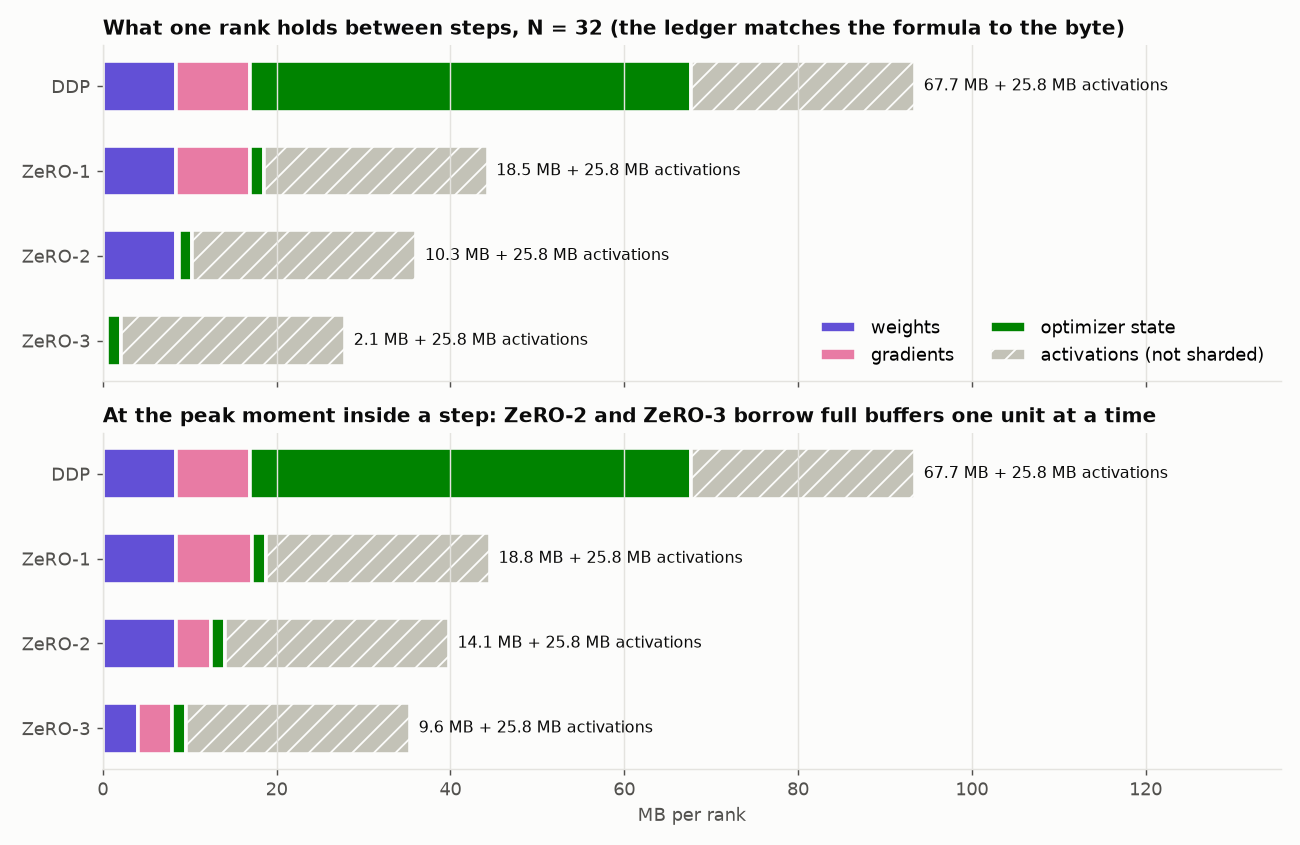

scaling


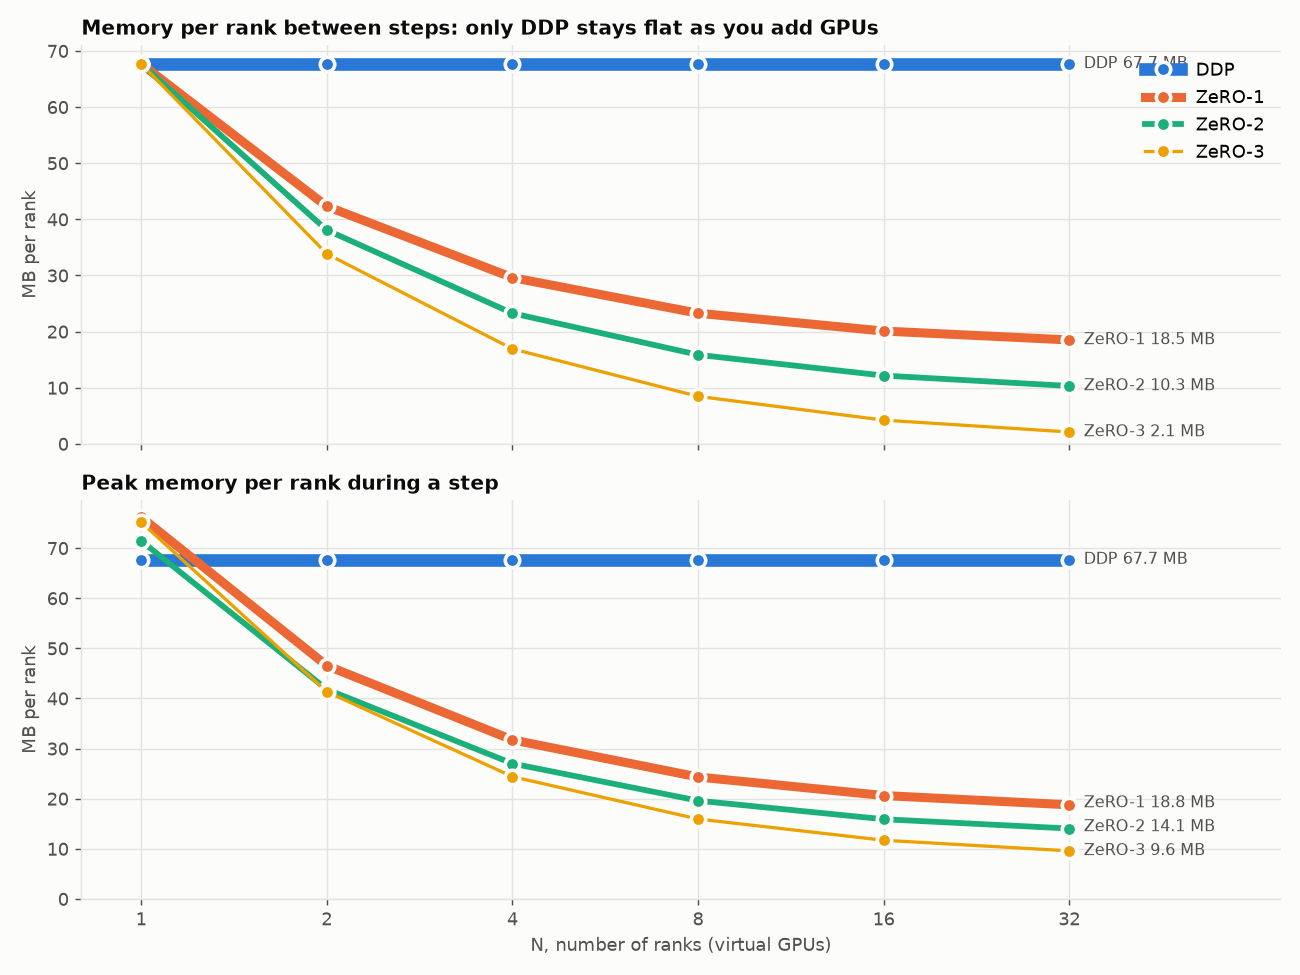

timeline


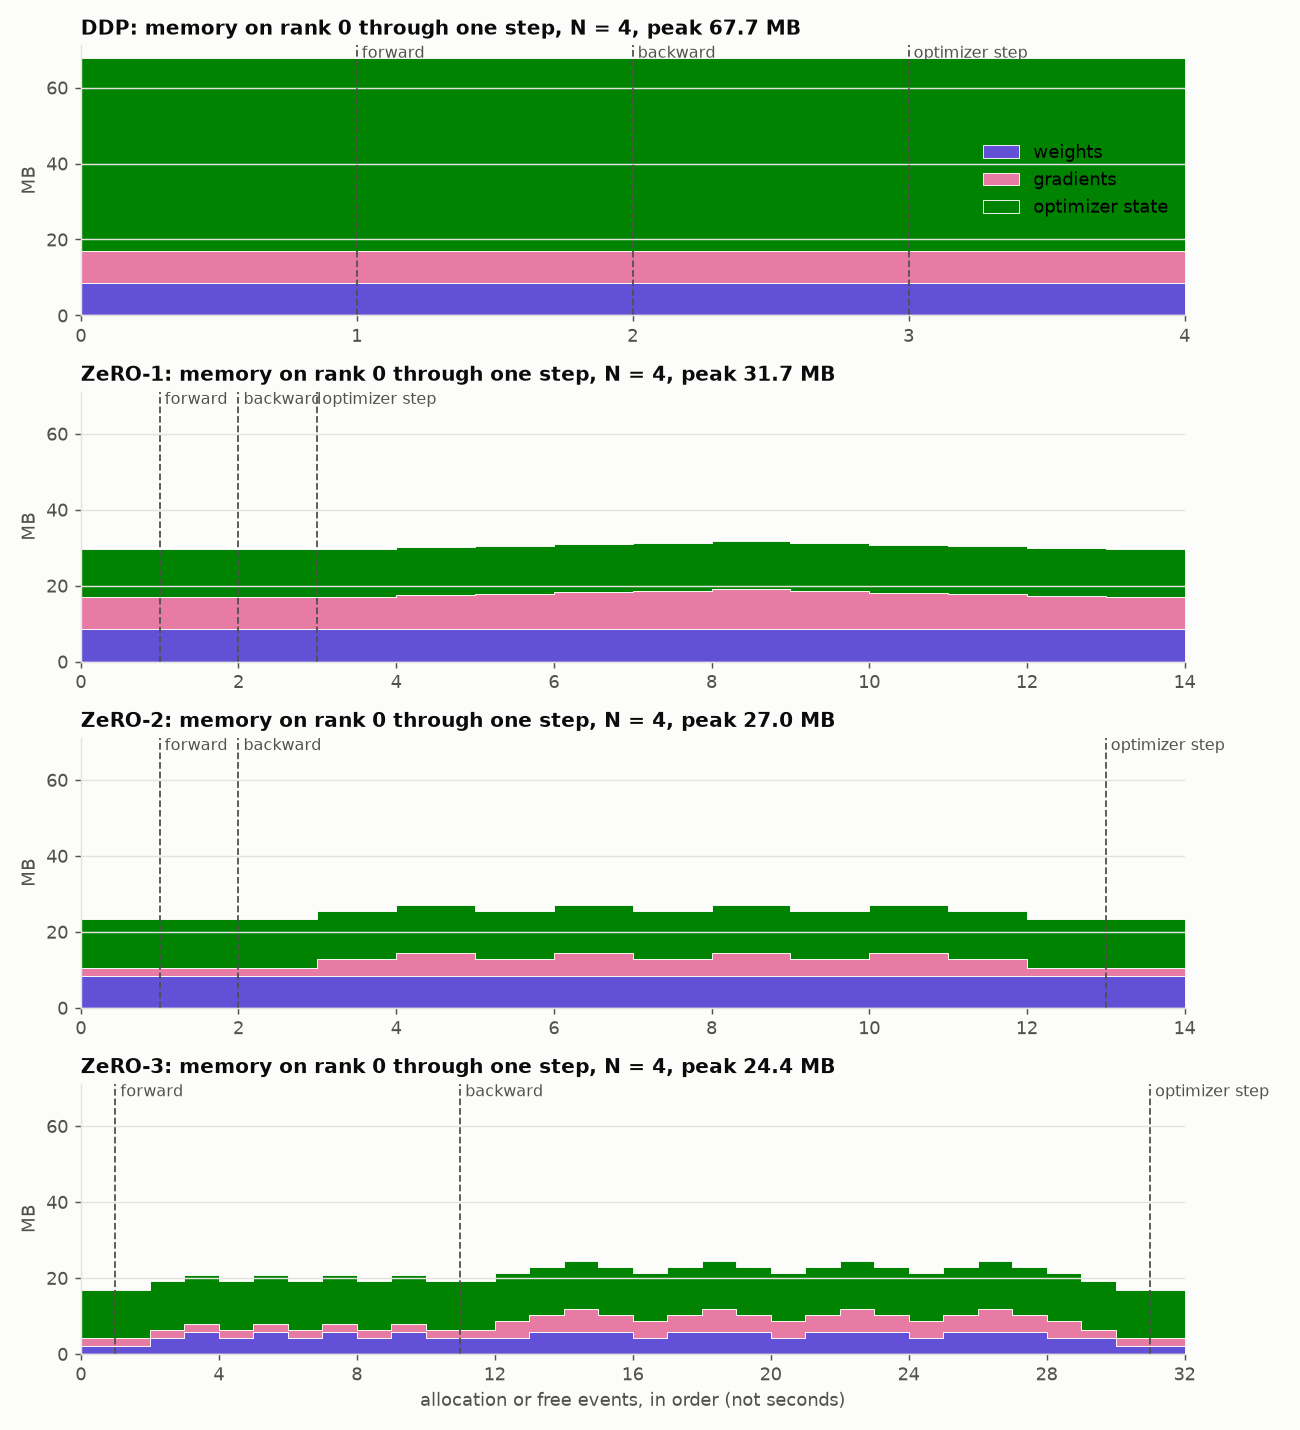

comm


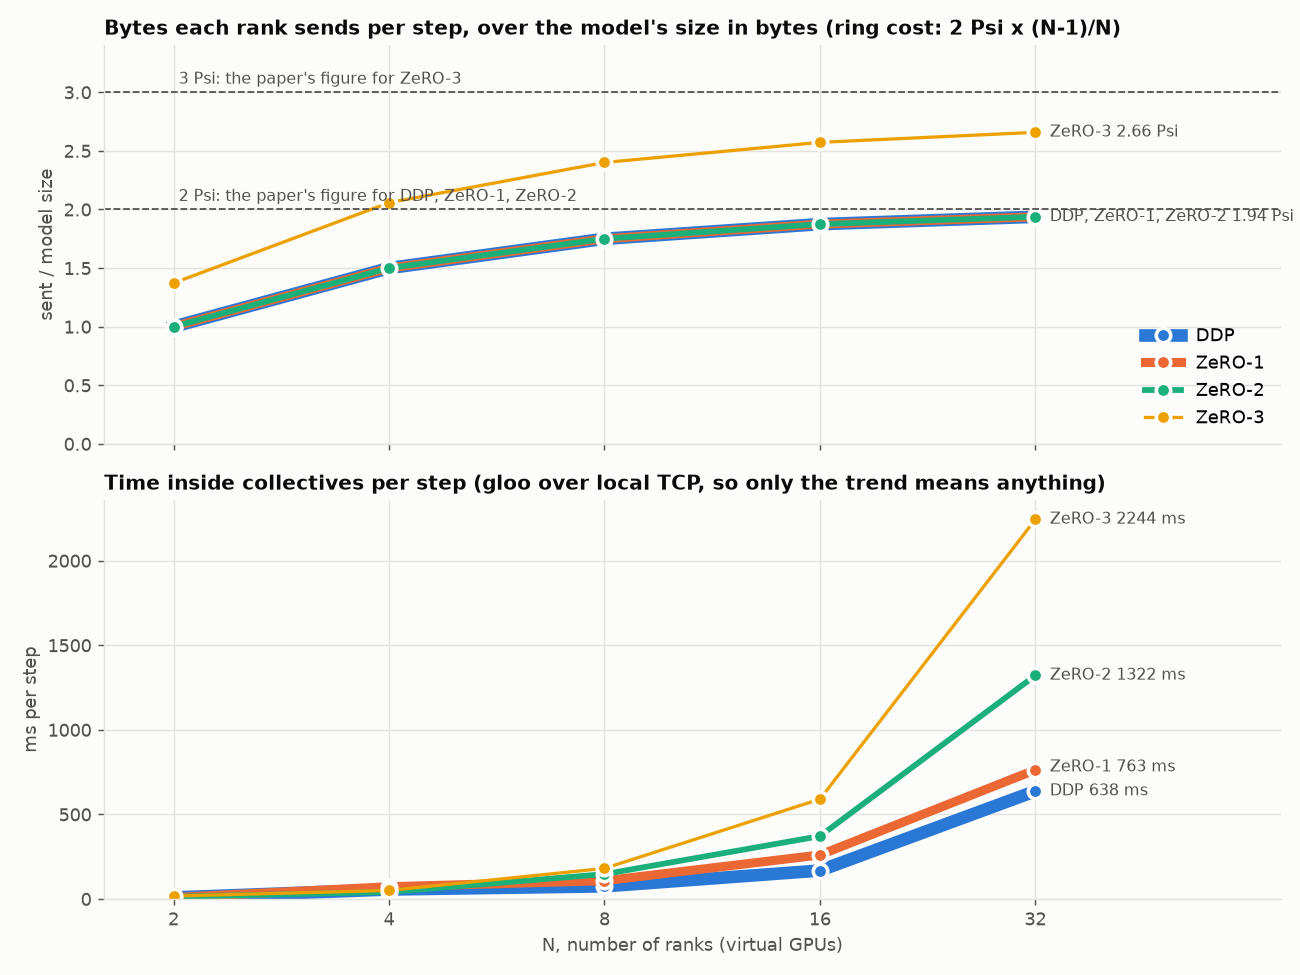

work


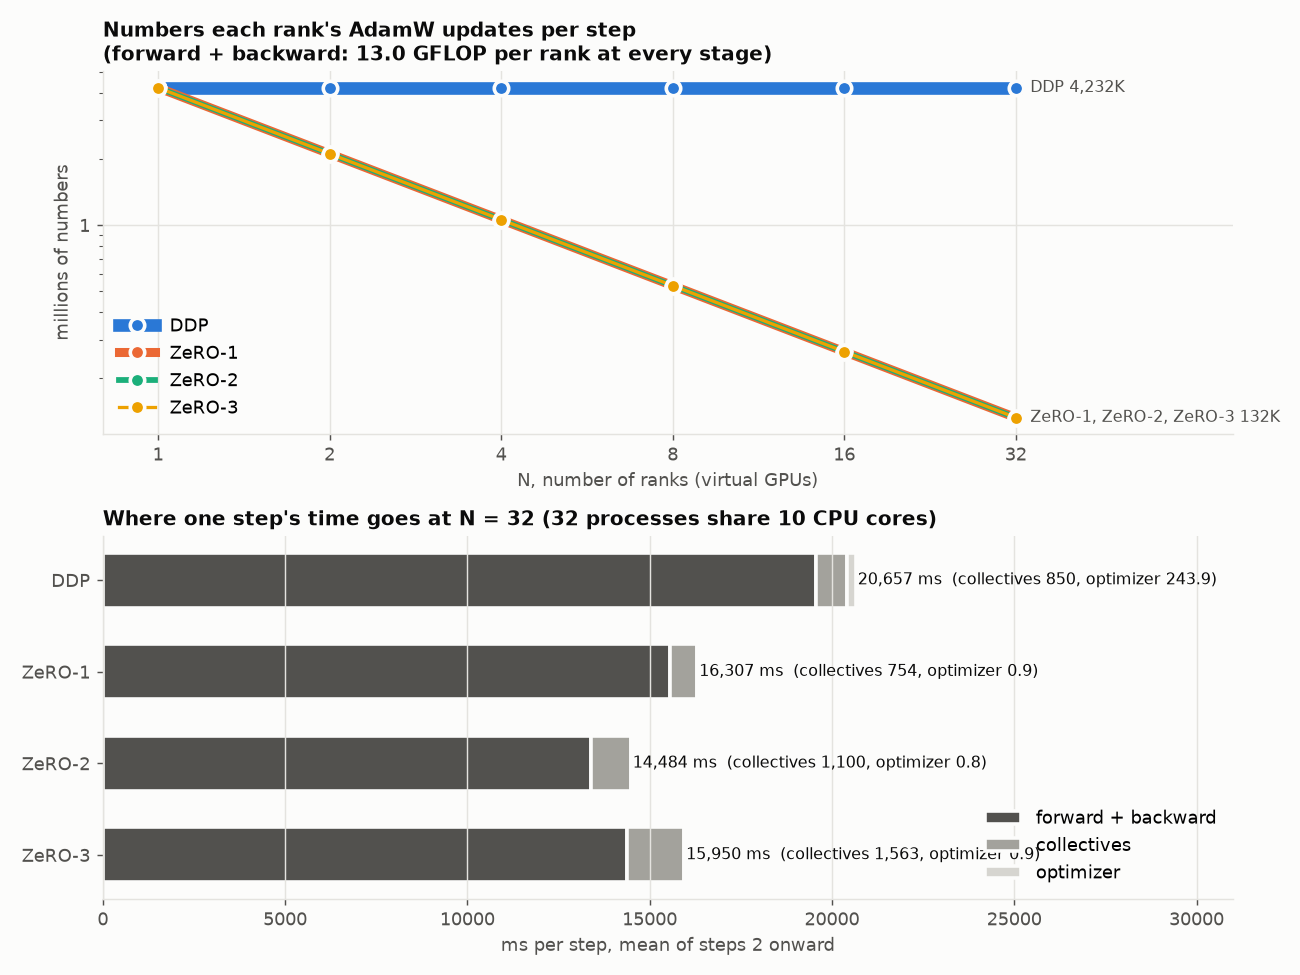

loss


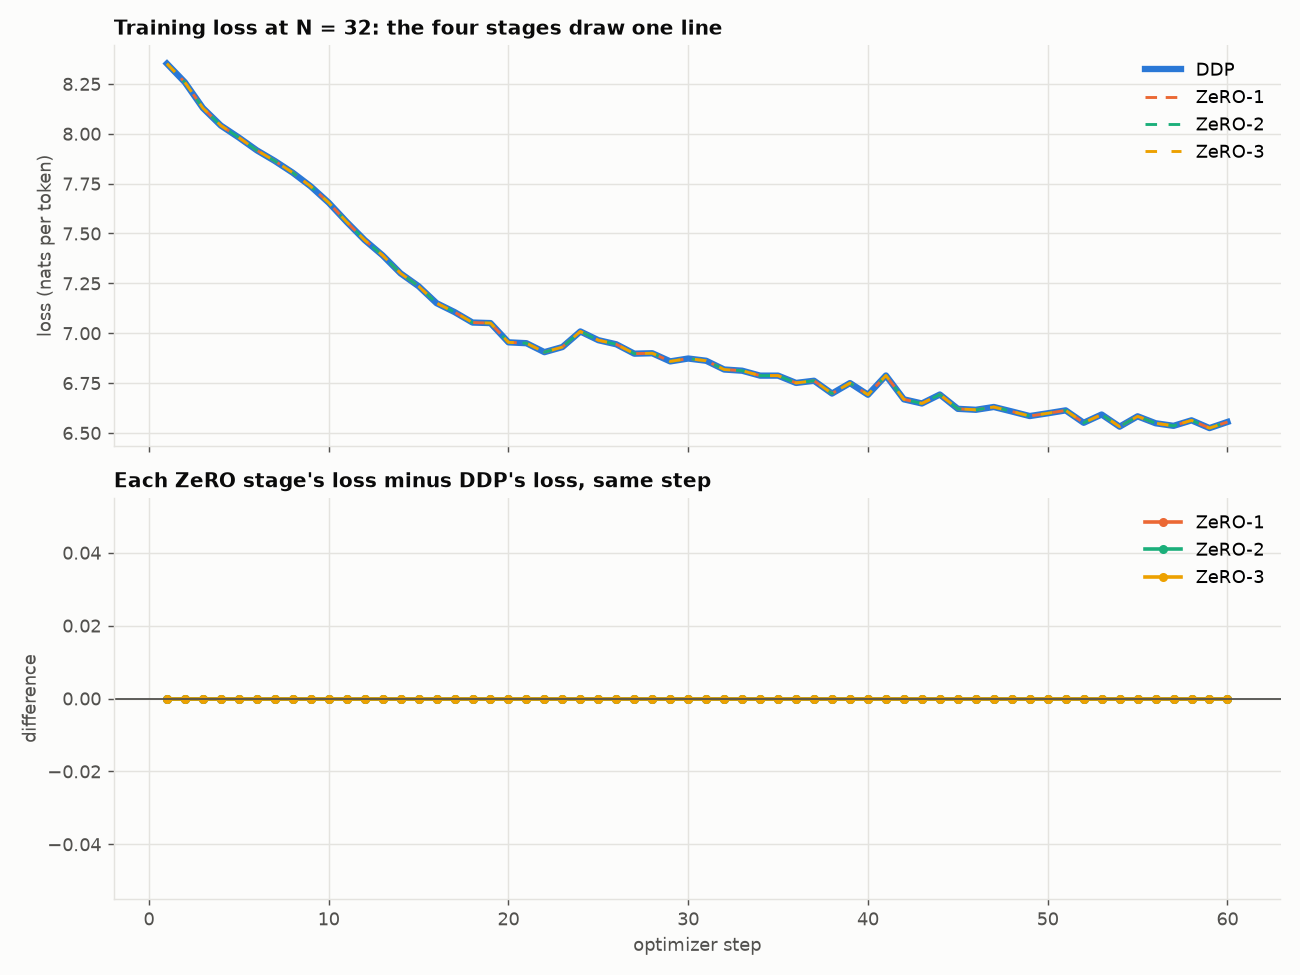

In [7]:
run("uv run plot.py --runs runs --out plots", log=None if RERUN else "runs/plot.log")
for name in ["memory", "scaling", "timeline", "comm", "work", "loss"]:
    print(name)
    display(Image(f"plots/{name}.png"))